# Symptom-Based Doctor Recommendation - ML Notebook
**Project:** AI-Powered Smart Healthcare Appointment & Assistance System  
**Task:** Predict the appropriate doctor *specialization* from free-text symptoms  
**Algorithm:** Logistic Regression (scikit-learn) on TF-IDF features

**Steps:** 1) Load data -> 2) Pre-process & encode -> 3) Train -> 4) Evaluate -> 5) Interpret -> 6) Save model

## 1. Imports

In [1]:
import re, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from text_utils import clean_text   # shared module so the saved model can be loaded by the backend
print("Libraries loaded")

Libraries loaded


## 2. Load the dataset
The dataset (`symptom_dataset.csv`) is produced by `generate_dataset.py` from a medical knowledge base of typical symptoms per specialization (shared symptoms, cross-specialty noise and 3% label noise are added to make it realistic).

In [2]:
df = pd.read_csv("symptom_dataset.csv").dropna()
print("Shape:", df.shape)
print(df.sample(8, random_state=1).to_string(index=False))
print("\nClass distribution:")
print(df.specialization.value_counts().to_string())

Shape: (4200, 2)
                                                                                                              symptoms    specialization
                                                                       experiencing tightness in chest while breathing     Pulmonologist
I think I have tightness in chest while breathing, child has fever, vomiting in toddler, also child not gaining weight      Pediatrician
                                                       feeling cold all the time, swelling in neck and extreme fatigue    ENT Specialist
                                                      fatigue, tiredness, shoulder pain, generally unwell, please help General Physician
                                                   Patient complains of frequent urination at night and blood in urine         Urologist
                                                           for two days I am having trouble sleeping, also mood swings      Psychiatrist
                        

## 3. Pre-processing & encoding
* **Cleaning:** lower-case, remove punctuation, collapse spaces  
* **Encoding text:** TF-IDF with unigrams + bigrams (e.g. "chest pain" is one feature)  
* **Encoding labels:** scikit-learn encodes the 14 specialization names internally

In [3]:
sample = ["I have CHEST pain,  palpitations & feel dizzy!!"]
print("Before:", sample[0])
print("After :", clean_text(sample)[0])

Before: I have CHEST pain,  palpitations & feel dizzy!!
After : i have chest pain palpitations feel dizzy


## 4. Train / test split (80 / 20, stratified)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.symptoms, df.specialization, test_size=0.2, stratify=df.specialization, random_state=42)
print("Train:", len(X_train), " Test:", len(X_test))

Train: 3360  Test: 840


## 5. Build the pipeline and train Logistic Regression

In [5]:
def build_pipeline():
    return Pipeline([
        ("clean", FunctionTransformer(clean_text, validate=False)),
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf",   LogisticRegression(max_iter=2000, C=5.0)),
    ])

model = build_pipeline().fit(X_train, y_train)
print("Vocabulary size:", len(model.named_steps["tfidf"].vocabulary_))
print("Classes:", list(model.classes_))

Vocabulary size: 2875
Classes: ['Cardiologist', 'Dermatologist', 'ENT Specialist', 'Endocrinologist', 'Gastroenterologist', 'General Physician', 'Gynecologist', 'Neurologist', 'Ophthalmologist', 'Orthopedic', 'Pediatrician', 'Psychiatrist', 'Pulmonologist', 'Urologist']


## 6. Evaluation

In [6]:
pred = model.predict(X_test)
acc = accuracy_score(y_test, pred)
f1 = f1_score(y_test, pred, average="macro")
print(f"Accuracy : {acc:.4f}")
print(f"Macro F1 : {f1:.4f}\n")
print(classification_report(y_test, pred))

Accuracy : 0.9512
Macro F1 : 0.9511

                    precision    recall  f1-score   support

      Cardiologist       0.97      0.93      0.95        61
     Dermatologist       0.97      0.98      0.98        61
    ENT Specialist       0.98      0.92      0.95        61
   Endocrinologist       0.94      0.97      0.95        60
Gastroenterologist       0.91      0.88      0.90        60
 General Physician       0.94      0.98      0.96        59
      Gynecologist       0.95      0.91      0.93        58
       Neurologist       1.00      0.95      0.97        60
   Ophthalmologist       0.91      0.97      0.94        60
        Orthopedic       0.95      0.95      0.95        59
      Pediatrician       0.95      0.93      0.94        61
      Psychiatrist       0.97      0.98      0.98        60
     Pulmonologist       0.92      0.95      0.93        60
         Urologist       0.98      1.00      0.99        60

          accuracy                           0.95       840
 

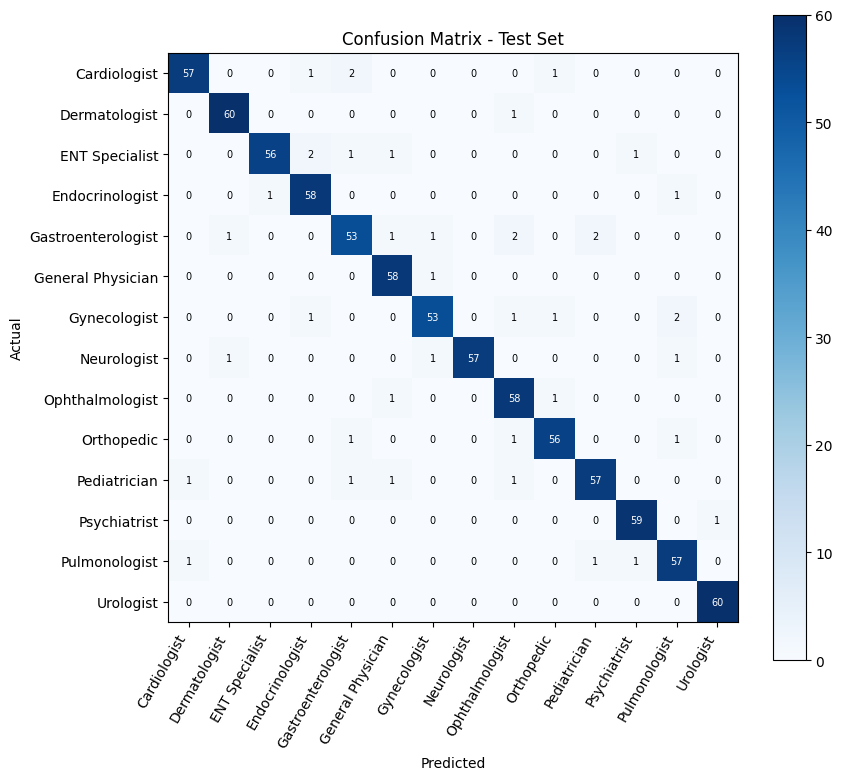

In [7]:
labels = sorted(df.specialization.unique())
cm = confusion_matrix(y_test, pred, labels=labels)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right"); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Confusion Matrix - Test Set")
fig.colorbar(im); plt.tight_layout(); plt.show()

In [8]:
cv = cross_val_score(build_pipeline(), df.symptoms, df.specialization, cv=5)
print("5-fold CV accuracy:", np.round(cv, 4))
print(f"Mean = {cv.mean():.4f}  (+/- {cv.std():.4f})")

5-fold CV accuracy: [0.9381 0.9333 0.9357 0.9548 0.944 ]
Mean = 0.9412  (+/- 0.0077)


## 7. Interpretability - which words drive each prediction?
Logistic Regression is a linear model, so the learned coefficients show the most influential words per specialization.

In [9]:
vec, clf = model.named_steps["tfidf"], model.named_steps["clf"]
names = np.array(vec.get_feature_names_out())
for cls, coefs in zip(clf.classes_, clf.coef_):
    print(f"{cls:20s}->", ", ".join(names[np.argsort(coefs)[-6:][::-1]]))

Cardiologist        -> chest, heartbeat, palpitations, chest tightness, and fainting, in legs
Dermatologist       -> skin, acne, hair loss, on, on skin, skin rash
ENT Specialist      -> nose, ear, sneezing, frequent sneezing, hearing loss, swollen tonsils
Endocrinologist     -> weight, excessive, extreme fatigue, extreme, frequent urination, increased
Gastroenterologist  -> acidity, constipation, indigestion, heartburn, bloating, stomach
General Physician   -> fever, weakness, chills, mild, tiredness, fatigue
Gynecologist        -> periods, pelvic, pelvic pain, pregnancy, pain during, during intercourse
Neurologist         -> seizures, migraine, headache, severe, severe headache, vertigo
Ophthalmologist     -> eyes, eye, vision, seeing, red eyes, headache after
Orthopedic          -> pain, joints, back pain, back, joint pain, joint
Pediatrician        -> child, has, baby, not, palpitations, toddler
Psychiatrist        -> irritability, depression, anxiety, excessive worry, worry, feelin

## 8. Try some predictions

In [10]:
tests = ["I have chest pain and palpitations", "itchy skin with red rash", "severe headache and numbness in hands",
         "burning during urination", "my son has fever and cough", "blurred vision and eye pain"]
proba = model.predict_proba(tests)
for t, p in zip(tests, proba):
    top = np.argsort(p)[::-1][:2]
    print(f"{t!r:45s}-> " + " | ".join(f"{model.classes_[i]} ({p[i]*100:.0f}%)" for i in top))

'I have chest pain and palpitations'         -> Cardiologist (82%) | Orthopedic (3%)
'itchy skin with red rash'                   -> Dermatologist (76%) | Ophthalmologist (10%)
'severe headache and numbness in hands'      -> Neurologist (99%) | Endocrinologist (0%)
'burning during urination'                   -> Urologist (93%) | Neurologist (1%)
'my son has fever and cough'                 -> Pediatrician (73%) | General Physician (10%)
'blurred vision and eye pain'                -> Ophthalmologist (96%) | Urologist (1%)


## 9. Save the final model
The final model is re-trained on **all** data and saved with joblib. The Flask backend loads this file (`ml_service.py`) - nothing is hard-coded.

In [11]:
final = build_pipeline().fit(df.symptoms, df.specialization)
joblib.dump(final, "symptom_model.joblib")
reloaded = joblib.load("symptom_model.joblib")
print("Saved symptom_model.joblib; reload test ->", reloaded.predict(["knee pain and swollen joints"])[0])

Saved symptom_model.joblib; reload test -> Orthopedic
